# 04 – Embeddings

Goal: turn job descriptions into vectors so a CV can be matched by meaning, not only by shared words.

1. Try the model on a few sentences.
2. Chunk descriptions (≤ 256 tokens).
3. Embed all chunks of the unique data jobs and save them.
4. Sanity check: do postings of the same role end up close together? (UMAP)
5. Match a sample CV to the nearest postings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("max tokens:", model.max_seq_length)

W1120 16:02:43.712000 15398 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

max tokens: 256


shape: (7, 384)


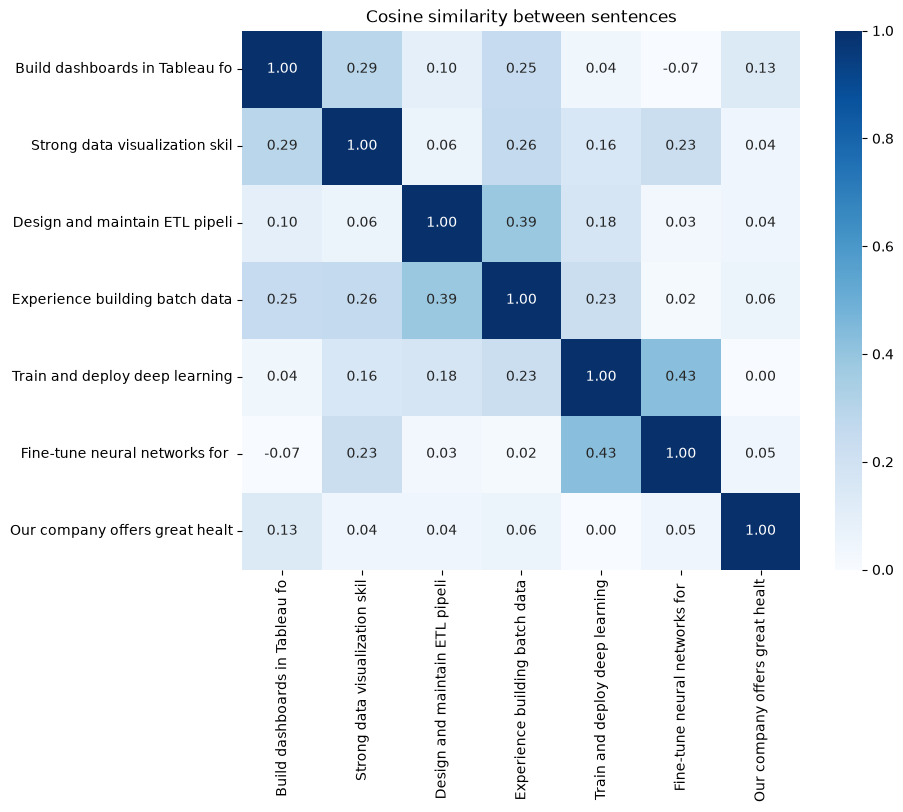

In [2]:
sentences = [
    "Build dashboards in Tableau for senior management",
    "Strong data visualization skills",
    "Design and maintain ETL pipelines with Airflow",
    "Experience building batch data workflows and orchestration",
    "Train and deploy deep learning models with PyTorch",
    "Fine-tune neural networks for computer vision",
    "Our company offers great health benefits and a 401(k)",
]

emb = model.encode(sentences, normalize_embeddings=True)
print("shape:", emb.shape)

sim = emb @ emb.T
labels = [s[:30] for s in sentences]

plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(sim, index=labels, columns=labels),
            annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cosine similarity between sentences")
plt.show()

### First test: 7 sentences

- Every paraphrase pair has its highest similarity with its partner (0.29, 0.39, 0.43) without shared words; the company-benefits sentence stays low with all (≤ 0.13).
- Absolute values are low and the visualization pair is only slightly above the next best (0.29 vs 0.26) → only the ranking matters; any threshold must be calibrated for this model.
- MiniLM is small and fast (6 layers); compare with a stronger embedding model in phase 2.

## Step 2: Chunking

In [3]:
import sys
sys.path.append("..")
from src.chunking import load_tokenizer, chunk_text

tok = load_tokenizer()
jobs = (pd.read_parquet("../data/processed/linkedin_data_jobs.parquet")
          .drop_duplicates("desc_group").reset_index(drop=True))

example = jobs.loc[3, "description"]
for i, c in enumerate(chunk_text(example, tok)):
    print(f"--- chunk {i} ({len(tok.encode(c).ids)} tokens)\n{c[:300]}\n")

--- chunk 0 (196 tokens)
Data Engineer with Kafka (W2 Only)💯% Remote Min 10 to12+ strong development experience neededVery strong experience in Kafka and Kafka data injection Strong exp in working with API. Strong exp in Python with AWS. Experience with Informatica IICS and Snowflake. Expertise in Snowflake's cloud data pla



In [4]:
jobs["chunks"] = jobs["description"].apply(lambda d: chunk_text(d, tok))
n_chunks = jobs["chunks"].str.len()
print("postings:", len(jobs), "| chunks:", n_chunks.sum())
print(n_chunks.describe().round(1))

chunk_tokens = jobs["chunks"].explode().apply(lambda c: len(tok.encode(c).ids))
print("\ntokens per chunk (with special tokens):")
print(chunk_tokens.describe().round(0))
print("chunks over 256 tokens:", (chunk_tokens > 256).sum())

postings: 2617 | chunks: 11897
count    2617.0
mean        4.5
std         2.5
min         1.0
25%         2.0
50%         4.0
75%         6.0
max        18.0
Name: chunks, dtype: float64

tokens per chunk (with special tokens):
count    11897.0
mean       167.0
std         42.0
min         15.0
25%        156.0
50%        184.0
75%        195.0
max        220.0
Name: chunks, dtype: float64
chunks over 256 tokens: 0


In [5]:
import textwrap

# A posting with 4 chunks (the median), printed with line wrapping
example = jobs[jobs["chunks"].str.len() == 4].iloc[0]
print(example["title"], "\n")
for i, c in enumerate(example["chunks"]):
    print(f"--- chunk {i} ({len(tok.encode(c).ids)} tokens)")
    print(textwrap.fill(c, width=120), "\n")

Data Science Software Engineer 

--- chunk 0 (185 tokens)
Company Overview Sovrinti is a full-service energy storage system supplier and integrator. Using our core strengths of
expert service to our customers, unparalleled safety, and excellence in manufacturing, we bring standardized, fully
integrated energy storage systems to a rapidly growing worldwide market. Our systems address our customers' needs to
reduce capital equipment and installation costs while enhancing system level performance and reliability using automated
monitoring systems and analytics across the battery, power conditioning and auxiliary systems. Our AEROS® energy
operating system is the engine of innovation to provide advanced control functions allowing our customers to maximize
the value of their energy storage assets. Our service capabilities include advanced monitoring and analytics, scheduled
maintenance, augmentation, and auxiliary system upgrades. The combination of excellence in battery technology and
prod

In [6]:
all_chunks = jobs["chunks"].explode()

tiny = all_chunks[chunk_tokens.values < 20]
print("chunks under 20 tokens:", len(tiny), f"({len(tiny) / len(chunk_tokens):.1%})")
print("chunks containing '##':", all_chunks.str.contains("##", regex=False).sum())

tiny.sample(min(15, len(tiny)), random_state=0).tolist()

chunks under 20 tokens: 1 (0.0%)
chunks containing '##': 0


['Skill Sets: SparkPyspark. TableauSQL Query']

### Chunking results

- 2,617 unique postings → 11,897 chunks (mean 4.5, median 4, max 18 per posting).
- Median chunk 184 tokens, min 15, max 220, 0 chunks over the 256-token limit.
- Units: lines, bullets, sentences (also "end.Next" glued without a space), greedily packed up to 200 tokens.
- Lines longer than 200 tokens are cut into word windows of max 100 tokens (never inside a word, original casing kept). A first version cut them in token windows and decoded them back, which produced broken pieces ("##fs.", "u. S.") and lone headings.
- A last chunk under 20 tokens is merged into the previous one. Only 1 tiny chunk remains (a very short posting).
- Example: in a typical 4-chunk posting the first chunk is only the company intro → for CV matching, the best chunk is a better signal than the mean of all chunks.

## Step 3: Embed all chunks

In [7]:
import time
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"
model = model.to(device)
print("device:", device)

# One row per chunk, in a fixed order: row i ↔ vector i
chunks = (jobs[["job_id", "desc_group", "title", "role", "level", "chunks"]]
            .explode("chunks")
            .rename(columns={"chunks": "text"})
            .reset_index(drop=True))
chunks["chunk_idx"] = chunks.groupby("job_id").cumcount()
print("chunks to embed:", len(chunks))

start = time.time()
chunk_emb = model.encode(chunks["text"].tolist(), batch_size=64,
                         normalize_embeddings=True, show_progress_bar=True,
                         convert_to_numpy=True)
print(f"shape {chunk_emb.shape} in {time.time() - start:.0f} s")
print("vector lengths (should be 1):", np.linalg.norm(chunk_emb[:5], axis=1).round(3))

device: mps
chunks to embed: 11897


Batches:   0%|          | 0/186 [00:00<?, ?it/s]

shape (11897, 384) in 23 s
vector lengths (should be 1): [1. 1. 1. 1. 1.]


In [9]:
# Mean pooling: one vector per posting = average of its chunk vectors
jobs_meta = (jobs[["job_id", "desc_group", "title", "company_name", "role", "level", "state", "salary"]]
               .reset_index(drop=True))

job_emb = (pd.DataFrame(chunk_emb)
             .groupby(chunks["job_id"].values).mean()
             .loc[jobs_meta["job_id"]]
             .to_numpy(dtype=np.float32))
job_emb = job_emb / np.linalg.norm(job_emb, axis=1, keepdims=True)
print("job vectors:", job_emb.shape)

job vectors: (2617, 384)


In [10]:
from pathlib import Path

OUT = Path("../data/processed")
chunks.to_parquet(OUT / "chunks.parquet", index=False)
np.save(OUT / "chunk_embeddings.npy", chunk_emb)
jobs_meta.to_parquet(OUT / "jobs_meta.parquet", index=False)
np.save(OUT / "job_embeddings.npy", job_emb)

for f in ["chunks.parquet", "chunk_embeddings.npy", "jobs_meta.parquet", "job_embeddings.npy"]:
    print(f, f"{(OUT / f).stat().st_size / 1e6:.1f} MB")

chunks.parquet 5.4 MB
chunk_embeddings.npy 18.3 MB
jobs_meta.parquet 0.1 MB
job_embeddings.npy 4.0 MB


In [11]:
i = 1234
fresh = model.encode([chunks.loc[i, "text"]], normalize_embeddings=True)[0]
print("same chunk, stored vs fresh:", round(float(fresh @ chunk_emb[i]), 4))
print("next chunk (different text):", round(float(fresh @ chunk_emb[i + 1]), 4))

same chunk, stored vs fresh: 1.0
next chunk (different text): 0.6852


### Embedding results

- 11,897 chunks embedded with all-MiniLM-L6-v2 on Apple MPS in 23 s (batch size 64), vectors normalized to length 1.
- Mean pooling (then re-normalized) → one vector per posting: 2,617 × 384.
- Saved to data/processed: chunks.parquet + chunk_embeddings.npy (row i ↔ vector i), jobs_meta.parquet + job_embeddings.npy.
- Spot check: re-embedding a stored chunk gives similarity ≈ 1.0 with its saved vector → rows and vectors are aligned.

## Step 4: Sanity check: do roles cluster?

/Users/rouzbehenayatzadeh/neuefische_bootcamp/skillscope/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/rouzbehenayatzadeh/neuefische_bootcamp/skillscope/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


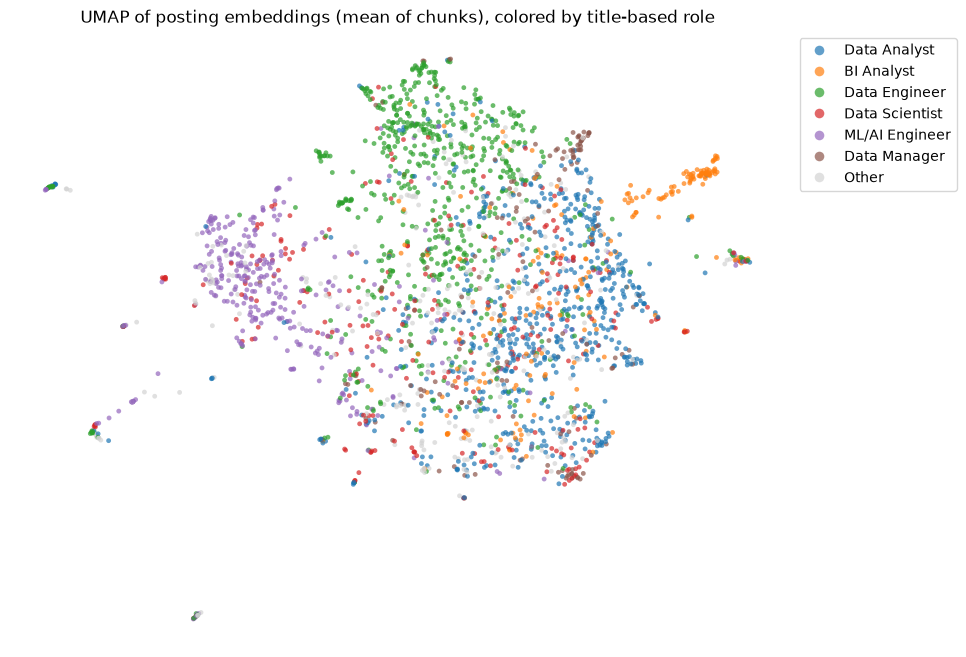

In [12]:
import umap

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42)
xy = reducer.fit_transform(job_emb)
jobs_meta["x"], jobs_meta["y"] = xy[:, 0], xy[:, 1]

roles_order = ["Data Analyst", "BI Analyst", "Data Engineer", "Data Scientist",
               "ML/AI Engineer", "Data Manager", "Other"]
palette = dict(zip(roles_order, sns.color_palette("tab10", len(roles_order))))
palette["Other"] = "lightgrey"

plt.figure(figsize=(10, 8))
sns.scatterplot(data=jobs_meta, x="x", y="y", hue="role", hue_order=roles_order,
                palette=palette, s=12, alpha=0.7, linewidth=0)
plt.title("UMAP of posting embeddings (mean of chunks), colored by title-based role")
plt.legend(markerscale=2, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.axis("off")
plt.show()

In [13]:
# For each posting: share of its 10 nearest neighbours (cosine) with the same role
sim = job_emb @ job_emb.T
np.fill_diagonal(sim, -1)          # a posting is not its own neighbour

k = 10
nn = np.argsort(-sim, axis=1)[:, :k]
roles_arr = jobs_meta["role"].to_numpy()
same_share = (roles_arr[nn] == roles_arr[:, None]).mean(axis=1)

knn = pd.DataFrame({"role": roles_arr, "same": same_share}).groupby("role")["same"].mean()
baseline = jobs_meta["role"].value_counts(normalize=True)
pd.DataFrame({"knn_same_role": knn, "random_baseline": baseline}).round(2) \
  .sort_values("knn_same_role", ascending=False)

,knn_same_role,random_baseline
role,,
Data Engineer,0.70,0.25
ML/AI Engineer,0.60,0.13
BI Analyst,0.50,0.09
Data Analyst,0.48,0.25
Data Scientist,0.33,0.11
Data Manager,0.30,0.06
Other,0.20,0.11


In [14]:
# Where do the 10 nearest neighbours of each role come from?
nn_roles = pd.DataFrame({"role": np.repeat(roles_arr, k), "neighbour_role": roles_arr[nn].ravel()})
pd.crosstab(nn_roles["role"], nn_roles["neighbour_role"], normalize="index").round(2)

neighbour_role,BI Analyst,Data Analyst,Data Engineer,Data Manager,Data Scientist,ML/AI Engineer,Other
role,,,,,,,
BI Analyst,0.50,0.23,0.13,0.02,0.06,0.02,0.04
Data Analyst,0.11,0.48,0.15,0.05,0.11,0.02,0.08
Data Engineer,0.04,0.10,0.70,0.03,0.05,0.03,0.04
Data Manager,0.04,0.24,0.21,0.30,0.08,0.01,0.13
Data Scientist,0.05,0.22,0.19,0.03,0.33,0.14,0.05
ML/AI Engineer,0.02,0.04,0.12,0.01,0.15,0.60,0.07
Other,0.06,0.24,0.20,0.08,0.09,0.13,0.20


In [15]:
# Near-duplicates the exact dedup missed: pairs of different postings with similarity > 0.95
pairs = np.argwhere(np.triu(sim, 1) > 0.95)
print("near-duplicate pairs:", len(pairs), "| postings involved:", len(np.unique(pairs)))
jobs_meta.loc[np.unique(pairs[:20]), ["company_name", "title", "role"]].head(15)

near-duplicate pairs: 260 | postings involved: 318


,company_name,title,role
16,EPITEC,Data Management Analyst,Data Manager
41,Avesta Computer Services,Senior ETL Data Engineer - Reinsurance - Remote,Data Engineer
64,Acro Service Corp,Data Analyst,Data Analyst
76,Discover Financial Services,Principal Business Data Steward,Data Manager
77,Discover Financial Services,Principal Business Data Steward (MarTech),Data Manager
82,Avesta Computer Services,Senior ETL Data Engineer (100% Remote),Data Engineer
84,Lightcast,Data Analyst (Korean),Data Analyst
85,Lightcast,Data Analyst (Chinese),Data Analyst
86,Lightcast,Data Analyst (Japanese),Data Analyst
90,Avesta Computer Services,Senior Data Engineer (Property Reinsurance/ Sp...,Data Engineer


### Sanity check results

- Without ever seeing titles or role labels, the embeddings put same-role postings together: share of the 10 nearest neighbours with the same role is far above random for every role (lift: BI 5.6×, Data Manager 5.0×, ML/AI 4.6×, Data Scientist 3.0×, Data Engineer 2.8×, Data Analyst 1.9×).
- UMAP shows the same picture: Data Engineer (top), ML/AI (left), BI (separate strand, right); Data Analyst is mixed; Data Scientist sits between ML/AI and analysts.
- Neighbour roles map the job market: Data Scientist sits between Data Analyst (0.22), Data Engineer (0.19) and ML/AI (0.14); ML/AI's closest other role is Data Scientist (0.15); Data Manager sits between analysts and engineers.
- 260 near-duplicate pairs (cosine > 0.95, 318 postings, 12%) survived exact dedup: same job with small title changes (Lightcast Korean / Chinese / Japanese) or one company template reused for different roles (Capital One). These are the small tight clusters at the UMAP edges.
- → CV matching must match on the best chunk (not the mean) and diversify results (max one posting per near-duplicate group / company).

## Step 5: Match a sample CV

In [16]:
cv_text = """
Junior Data Scientist

Recent graduate of a 4-month data science bootcamp with a background in economics.

Skills: Python, pandas, NumPy, scikit-learn, SQL, Tableau, statistics, hypothesis testing,
A/B testing, regression and classification models, XGBoost, Git, Jupyter.

Projects:
- Built a churn prediction model for a telecom dataset with scikit-learn and XGBoost,
  tuned with cross-validation and explained with SHAP values.
- Analysed an online shop A/B test in Python and presented the results to stakeholders
  in a Tableau dashboard.
- Classified customer reviews by topic using sentence embeddings and logistic regression.

Experience:
Business Analyst Intern, retail company (6 months): wrote SQL queries for weekly sales
reports, cleaned data in Excel and pandas, and built KPI dashboards.
"""

cv_chunks = chunk_text(cv_text, tok)
cv_vec = model.encode(cv_chunks, normalize_embeddings=True).mean(axis=0)
cv_vec = cv_vec / np.linalg.norm(cv_vec)
print("CV chunks:", len(cv_chunks))

CV chunks: 1


In [17]:
# Score every chunk, keep the best chunk per posting
scored = chunks[["job_id", "chunk_idx", "text"]].assign(score=chunk_emb @ cv_vec)
best = scored.sort_values("score", ascending=False).drop_duplicates("job_id")

ranking = best.merge(jobs_meta[["job_id", "title", "company_name", "role", "level", "state", "salary"]],
                     on="job_id")
print("postings ranked:", len(ranking))
ranking.head(10)[["score", "title", "company_name", "role", "chunk_idx"]].round(3)

postings ranked: 2617


,score,title,company_name,role,chunk_idx
0,0.683,"Senior Data Analyst, Pricing",Paysafe,Data Analyst,3
1,0.683,Entry Level Data Scientist,topGrads,Data Scientist,0
2,0.679,SR Data Scientist,BJ's Wholesale Club,Data Scientist,2
3,0.657,Sr. Staff Data Analyst - Marketing Analytics,Achieve,Data Analyst,3
4,0.653,Director of Business Analytics,Above Lending,Data Analyst,1
5,0.653,VP Data Science,EvolutionIQ,Data Scientist,3
6,0.650,Junior Data Analytics Engineer,ICE,Data Engineer,1
7,0.650,Data Scientist,Cephas Consultancy Services Private Limited,Data Scientist,0
8,0.650,Business Data Analyst,Catapult Solutions Group,Data Analyst,3
9,0.644,"Senior/Lead Data Analyst, Finance & Strategy",Chime,Data Analyst,2


In [22]:
def diversify(ranked, n=10, levels=None, max_sim=0.95):
    """Top n postings: optional level filter, max one per company, no near-duplicates."""
    selected, seen_companies = [], set()
    for row in ranked.itertuples():
        if levels is not None and row.level not in levels:
            continue
        company = str(row.company_name)
        if company in seen_companies:
            continue
        v = job_emb[job_pos[row.job_id]]
        if any(float(v @ job_emb[job_pos[s]]) > max_sim for s in selected):
            continue
        selected.append(row.job_id)
        seen_companies.add(company)
        if len(selected) == n:
            break
    return ranked.set_index("job_id").loc[selected].reset_index()


junior_levels = {"Intern", "Junior", "Mid-Senior", "Unknown"}
top = diversify(ranking, levels=junior_levels)
top[["score", "title", "company_name", "role", "level", "salary", "chunk_idx"]].round(3)

,score,title,company_name,role,level,salary,chunk_idx
0,0.683,Entry Level Data Scientist,topGrads,Data Scientist,Junior,NaN,0
1,0.650,Junior Data Analytics Engineer,ICE,Data Engineer,Junior,NaN,1
2,0.650,Data Scientist,Cephas Consultancy Services Private Limited,Data Scientist,Unknown,NaN,0
3,0.650,Business Data Analyst,Catapult Solutions Group,Data Analyst,Mid-Senior,133712.8,3
4,0.641,Data Scientist,Adobe,Data Scientist,Junior,150100.0,2
5,0.638,"Data Science Intern, Summer 2024",Edwards Lifesciences,Data Scientist,Intern,63000.0,2
6,0.636,Data Operations Analyst,Convey Health Solutions,Data Analyst,Mid-Senior,NaN,1
7,0.635,"Data Science Reporting Analyst in Columbus, OH",Central Point Partners,Data Scientist,Mid-Senior,NaN,2
8,0.635,BI Analyst,Dice,BI Analyst,Mid-Senior,NaN,1
9,0.631,Data Operations Specialist (E-Commerce),Chery Group,Other,Junior,46498.4,1


In [23]:
for row in top.head(3).itertuples():
    print(f"=== {row.title} @ {row.company_name} | {row.level} | score {row.score:.3f} | chunk {row.chunk_idx}")
    print(textwrap.fill(row.text[:600], width=120), "\n")

=== Entry Level Data Scientist @ topGrads | Junior | score 0.683 | chunk 0
Responsibilities: Assemble, analyze, and interpret large data collected from multiple sources including phone calls,
website, email, and surveys to measure student ROI. Build Machine Learning (ML) models leveraging the latest algorithms
in Google Cloud Platform to predict conversion likelihood, faculty performance, student/learner success and/or
persistence. Develop Natural Language Processing (NLP) models to evaluate student readiness, conduct sentiment analyses
to better understand student/learner’s delights and pain points. Identify opportunities across the organization and
leverage predict 

=== Junior Data Analytics Engineer @ ICE | Junior | score 0.650 | chunk 1
Assist in the creation of data driven solutions for business and generate actionable business insight Use data to create
models that depicts trends and patterns of informationProcess and analyze large volumes of data Story board, create, and
publis

### Matching results (sample junior data scientist CV)

- CV → 1 chunk → 1 vector. Each posting is scored by its best chunk (max pooling): in 8 of the top 10 the best chunk was not the first one, so the company intro did not drag the score down.
- Without filters the roles were right (5 Data Analyst, 4 Data Scientist, 1 junior analytics engineer) but the levels were wrong (Senior, Director, VP): embeddings capture the topic of a job, not its seniority.
- Hybrid search = semantic score + level filter (Intern, Junior, Mid-Senior, Unknown) + diversification (max one posting per company, no near-duplicates above 0.95) → 5 Intern / Junior, 5 Mid-Senior / Unknown; the 10th score only dropped from 0.644 to 0.631.
- The best chunk explains each match (e.g. ICE: Python, SQL for ad-hoc analysis, reports and visualizations).
- Only 4 of the 10 matches have a salary → the salary model will estimate the rest.